# ME249 Fall 2026 - Project 2 - Tasks 2.4 and 2.5
**Genetic algorithm determination of (UA)e, (UA)c and alpha for the heat-pipe heat exchanger model, Eq. (2.3)**

* Cell 1: CodeP2.3F26 (122 heat pipe data points) + random 80 % / 20 % training / validation split.
* Cell 2: genetic algorithm (copy of the Task 2.2 program) with the heat transfer rate error function, Eqs. (2.4)-(2.6) - see header.
* Cell 3: figure style (added).
* Cell 4: Task 2.5 - initial guesses of order 1, mutation amplitude, selection threshold MFRAC and number of generations NGEN.
* Cell 5: best fit, training / validation errors, log-log plots and surface plot.
* Cell 6: identifiability of (UA)e, (UA)c and alpha (error valley).

In [1]:
'''>>>>> start CodeP2.3F26
    V.P. Carey ME249, Fall 2026
    MODIFIED for Tasks 2.4 / 2.5:
      - matplotlib imported (plots are made in this program)
      - the 122 data points are kept in yalldata and randomly split (fixed seed,
        reproducible) into a training set (ydata, ND = 98 points, about 80 %) and a
        validation set (vdata, NV = 24 points, about 20 %); the genetic algorithm
        only uses ydata, as the Task 2.2 program does

    Heat pipe performance data for Part 2 of Project 2
   122 data points'''

# version 3 print function
from __future__ import print_function
# seed the pseudorandom number generator
from random import random
from random import seed
# seed random number generator
seed(1)

#import math and numpy packages
import math
import numpy as np
import numpy

%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [10, 8] # for square canvas

#import copy
from copy import copy, deepcopy


#create array 
ydata = []


# j is column, i is row downward for ydata[i][j] - both start at zero
# so it is:  ydata[row][column]
# this is an array that is essentially a list of lists

#assembling heat pipe performance data array
#==========================================
#store array where rows are data vectors 
#[Ta,in(deg C), Ta,out(deg C), qdot(W)] 

ydata =     [[ 27.2,     15.9,      31.2]]
ydata.append([ 29.6,     17.1,      37.0])
ydata.append([ 29.5,     18.1,      34.2])
ydata.append([ 30.4,     19.0,      31.])
ydata.append([ 30.4,     20.0,      28.5])
ydata.append([ 30.2,     21.0,      25.7])
ydata.append([ 29.8,     22.1,      22.8])
ydata.append([ 29.8,     22.9,      20.0])
ydata.append([ 29.9,     24.1,      17.1])
ydata.append([ 29.6,     24.9,      14.3])
ydata.append([ 29.5,     26.1,      11.4])
ydata.append([ 30.3,     26.9,       8.6])
ydata.append([ 32.5,     16.9,      45.7])
ydata.append([ 32.6,     18.1,      42.8])
ydata.append([ 32.6,     19.1,      40.0])
ydata.append([ 32.7,     20.2,      37.2])
ydata.append([ 32.9,     21.1,      34.3])
ydata.append([ 33.0,     22.0,      31.5])
ydata.append([ 32.5,     23.1,      28.7])
ydata.append([ 32.8,     24.1,      25.8])
ydata.append([ 33.0,     24.9,      23.0])
ydata.append([ 32.9,     26.0,      20.1])
ydata.append([ 33.1,     27.0,      17.2])
ydata.append([ 35.7,     17.0,      54.4])
ydata.append([ 35.6,     18.1,      51.6])
ydata.append([ 36.2,     19.1,      48.7])
ydata.append([ 36.3,     20.2,      45.9])
ydata.append([ 36.4,     21.1,      43.1])
ydata.append([ 35.5,     22.2,      40.2])
ydata.append([ 36.2,     22.9,      37.4])
ydata.append([ 36.2,     24.1,      34.5])
ydata.append([ 35.7,     25.0,      31.7])
ydata.append([ 36.0,     26.1,      28.8])
ydata.append([ 35.8,     27.1,      25.9])
ydata.append([ 38.8,     16.9,      63.1])
ydata.append([ 39.4,     18.1,      60.3])
ydata.append([ 38.9,     19.2,      57.5])
ydata.append([ 39.2,     20.1,      54.7])
ydata.append([ 38.5,     21.2,      51.8])
ydata.append([ 39.0,     22.0,      49.0])
ydata.append([ 39.0,     23.1,      46.1])
ydata.append([ 39.3,     24.0,      43.3])
ydata.append([ 39.3,     24.9,      40.4])
ydata.append([ 39.1,     26.2,      37.6])
ydata.append([ 39.1,     27.2,      34.7])
ydata.append([ 42.2,     17.0,      71.9])
ydata.append([ 42.3,     18.1,      69.1])
ydata.append([ 42.4,     18.9,      66.3])
ydata.append([ 41.9,     20.0,      63.5])
ydata.append([ 41.8,     21.0,      60.6])
ydata.append([ 41.8,     22.1,      57.8])
ydata.append([ 42.2,     22.8,      54.9])
ydata.append([ 41.5,     24.2,      52.1])
ydata.append([ 42.3,     25.3,      49.2])
ydata.append([ 41.8,     25.9,      46.3])
ydata.append([ 42.3,     26.8,      43.5])
ydata.append([ 45.2,     17.1,      80.8])
ydata.append([ 44.5,     18.2,      78.0])
ydata.append([ 44.8,     18.8,      75.1])
ydata.append([ 45.2,     20.0,      72.3])
ydata.append([ 44.9,     21.2,      69.5])
ydata.append([ 45.3,     22.1,      66.6])
ydata.append([ 44.5,     22.8,      63.8])
ydata.append([ 44.9,     24.1,      60.9])
ydata.append([ 44.8,     25.2,      58.1])
ydata.append([ 45.3,     26.2,      55.2])
ydata.append([ 44.9,     26.9,      52.3])
ydata.append([ 48.0,     17.2,      89.7])
ydata.append([ 47.7,     18.1,      86.9])
ydata.append([ 48.2,     18.9,      84.0])
ydata.append([ 48.3,     19.9,      81.2])
ydata.append([ 48.0,     20.0,      78.3])
ydata.append([ 48.4,     22.8,      75.5])
ydata.append([ 48.2,     23.0,      72.7])
ydata.append([ 47.6,     24.0,      69.8])
ydata.append([ 48.2,     25.1,      66.9])
ydata.append([ 48.2,     25.8,      64.1])
ydata.append([ 47.8,     26.9,      61.2])
ydata.append([ 50.5,     17.0,      98.6])
ydata.append([ 50.6,     18.0,      95.8])
ydata.append([ 50.5,     19.1,      93.0])
ydata.append([ 50.9,     20.1,      90.1])
ydata.append([ 51.0,     20.8,      87.3])
ydata.append([ 51.0,     21.9,      84.4])
ydata.append([ 50.5,     23.0,      81.6])
ydata.append([ 51.2,     24.1,      78.7])
ydata.append([ 50.8,     25.2,      75.9])
ydata.append([ 51.2,     25.9,      73.0])
ydata.append([ 51.0,     26.9,      70.1])
ydata.append([ 54.2,     17.1,     107.6])
ydata.append([ 53.5,     18.1,     104.8])
ydata.append([ 54.1,     19.1,     101.9])
ydata.append([ 53.5,     20.1,      99.1])
ydata.append([ 53.5,     21.2,      96.3])
ydata.append([ 54.2,     21.9,      93.4])
ydata.append([ 54.1,     23.2,      90.6])
ydata.append([ 53.8,     24.1,      87.7])
ydata.append([ 53.6,     25.0,      84.8])
ydata.append([ 53.9,     26.0,      82.0])
ydata.append([ 53.7,     26.8,      79.1])
ydata.append([ 57.2,     17.0,     116.7])
ydata.append([ 56.9,     18.1,     113.8])
ydata.append([ 57.0,     19.1,     111.0])
ydata.append([ 56.7,     19.8,     108.1])
ydata.append([ 57.3,     20.9,     105.3])
ydata.append([ 56.8,     21.9,     102.4])
ydata.append([ 57.4,     23.2,      99.6])
ydata.append([ 57.3,     23.8,      96.7])
ydata.append([ 56.6,     25.2,      93.8])
ydata.append([ 57.0,     25.8,      91.0])
ydata.append([ 57.2,     27.0,      88.1])
ydata.append([ 60.2,     16.9,     125.7])
ydata.append([ 59.9,     17.9,     122.9])
ydata.append([ 59.6,     19.1,     120.0])
ydata.append([ 60.2,     20.1,     117.2])
ydata.append([ 60.2,     20.9,     114.3])
ydata.append([ 60.4,     21.8,     111.5])
ydata.append([ 59.1,     22.9,     108.6])
ydata.append([ 59.1,     24.1,     105.8])
ydata.append([ 60.1,     25.2,     102.9])
ydata.append([ 59.1,     25.8,     100.0])
ydata.append([ 60.3,     26.9,      97.1])


#==========================================
# random 80 % / 20 % split into training and validation sets
#==========================================
yalldata = deepcopy(ydata)
NALL = len(yalldata)                 # 122 data points
NV = int(round(0.2*NALL))            # 24 validation points
ND = NALL - NV                       # 98 training points
NS = ND                              # number of DNA strands = number of training points
DI = 3                               # number of data items in vector

rng_split = np.random.RandomState(2026)          # fixed seed -> reproducible split
perm = rng_split.permutation(NALL)
ival = sorted(perm[:NV])                         # indices of validation points
itrain = sorted(perm[NV:])                       # indices of training points
ydata = [yalldata[i] for i in itrain]            # training data used by the GA
vdata = [yalldata[i] for i in ival]              # validation data (never used in the GA)

print('total data points NALL =', NALL, ' training ND =', ND, ' validation NV =', NV)
print('validation set indices:', ival)

#end CodeP2.3F26


total data points NALL = 122  training ND = 98  validation NV = 24
validation set indices: [np.int64(4), np.int64(10), np.int64(16), np.int64(18), np.int64(34), np.int64(42), np.int64(44), np.int64(53), np.int64(57), np.int64(62), np.int64(66), np.int64(72), np.int64(80), np.int64(84), np.int64(86), np.int64(87), np.int64(92), np.int64(99), np.int64(103), np.int64(106), np.int64(111), np.int64(113), np.int64(119), np.int64(120)]


In [2]:
'''>>>>> start CodeP2.2F26
    V.P. Carey ME249, Fall 2026
    MODIFIED for Tasks 2.4 / 2.5 (heat pipe model, Eqs. 2.3-2.6) - copy of the Task 2.2
    program in which:
      - the data are the heat pipe data of CodeP2.3F26 (training set ydata, ND points)
      - n1 = (UA)e, n2 = (UA)c, n3 = alpha ; n0 = -1 and n4, n5 are not used
      - the error function (2 locations: fitness loop and population-average loop)
        is the fractional error of the heat transfer rate, Eqs. (2.4)-(2.5):
          aFerr_i = | qdot_data,i - qdot_model(n1,n2,n3,Ta_in,i,Ta_out,i) | / | qdot_data,i |
      - the mean absolute error of the validation set (vdata) is also computed at
        each generation with the population-average constants (not used for selection)
    and, as in Task 2.2:
      - the evolution loop of the skeleton code is placed, unchanged, inside a
        function run_GA(...) so that it can be re-run for several initial guesses,
        mutation amplitudes, numbers of generations and random seeds
      - the maximum mutation amplitude (0.085 in the skeleton) is now the
        argument MUT (relative amplitude, i.e. +/- MUT*100 %)
      - both random generators (python random and numpy.random) are seeded with
        the argument rseed so that every run is reproducible
      - the history of the population-average constants and of aFerrmeanavgn is
        returned, together with the generation at which aFerrmeanavgn first drops
        below the target value (convergence-speed indicator) and the number of
        survivors nkeep of each generation (selection diagnostic)
      - BUG FIX: the skeleton line "import random" re-binds the name random to the
        module and hides the function random() imported in CodeP2.1F26, so the
        initialisation n1i+0.001*random() raises "TypeError: 'module' object is
        not callable".  The line is replaced by an explicit import of the function.'''
from random import random, seed   # (was: import random)

sigma = 5.67e-8     # Stefan-Boltzmann constant, W m-2 K-4
hcref = 80.0        # reference convective coefficient of condenser fin section, W m-2 K-1

def hrad(Tain, Taout):
    '''radiation coefficient h_r = sigma (Tin + Tout)(Tin^2 + Tout^2), absolute temperatures'''
    Ti = Tain + 273.15
    To = Taout + 273.15
    return sigma*(Ti + To)*(Ti**2 + To**2)

def qdot_model(n1, n2, n3, Tain, Taout):
    '''Eq. (2.6): qdot = n2 (1 + n3 hr/hcref) [ n1 (Tain - Taout) / ( n1 + n2 (1 + n3 hr/hcref) ) ]'''
    UAcr = n2*(1. + n3*hrad(Tain, Taout)/hcref)
    return UAcr*( n1*(Tain - Taout)/(n1 + UAcr) )

def run_GA(n1i, n2i, n3i, n4i=1.0, n5i=1.0, NGEN=6000, MUT=0.09, MFRAC=0.5,
           rseed=1, target=0.045, verbose=True):

    '''INITIALIZING PARAMETERS'''
    seed(rseed)                 # python random  (initial population)
    numpy.random.seed(rseed)    # numpy random   (mating / mutation)
    n = []
    ntemp = []
    gen=[0]
    n1avg = [0.0]
    n2avg = [0.0]
    n3avg = [0.0]
    n4avg = [0.0]
    n5avg = [0.0]
    meanAFerr=[0.0]
    aFerrmeanavgn=[0.0]
    aFerrval=[0.0]

    # here the number of data vectors equals the number of DNA strands (or organisms)
    for k in range(NGEN-1):
        gen.append(k+1)   # generation array stores the
        meanAFerr.append(0.0)
        aFerrmeanavgn.append(0.0)
        aFerrval.append(0.0)
        n1avg.append(0.0)
        n2avg.append(0.0)
        n3avg.append(0.0)
        n4avg.append(0.0)
        n5avg.append(0.0)

    '''guesses for initial solution population: n0i = -1 (fixed), n1i ... n5i are arguments'''
    n0i =  -1.0

    #i initialize array where rows are dna vectors [n0i,n1i,...n5i] with random pertubations
    n =  [[-1., n1i+0.001*random(), n2i+0.1*random(), n3i+0.0001*random(), n4i+0.0001*random(), n5i+0.0001*random()]]
    for i in range(ND):
        n.append([-1., n1i+0.0001*random(), n2i+0.001*random(), n3i+0.0001*random(), n4i+0.0001*random(), n5i+0.0001*random()])

    # store also in wtemp
    ntemp = deepcopy(n)

    #define arrays of Ferr (error) functions
    Ferr =  [[0.0]]
    Ferravgn =  [[0.0]]
    aFerr =  [[0.0]]
    aFerravgn =  [[0.0]]
    for i in range(ND-1):
        Ferr.append([0.0])
        aFerr.append([0.0])
        Ferravgn.append([0.0])
        aFerravgn.append([0.0])

    aFerrmeanavgnMin=1000000000.0
    # these store the  n values for minimum population average error durng NGEN generations
    n1min = 0.0
    n2min = 0.0
    n3min = 0.0
    n4min = 0.0
    n5min = 0.0
    kmin = 0
    aFerrvalmin = 0.0
    aFerrta = 0.0
    # these store the time averaged n values durng from generation 800 to NGEN generations
    n1ta = 0.0
    n2ta = 0.0
    n3ta = 0.0
    n4ta = 0.0
    n5ta = 0.0
    kconv = -1      # first generation with aFerrmeanavgn < target (-1 = never)
    nkeephist = []  # (added) number of survivors nkeep at each generation

    '''START OF EVOLUTION LOOP'''
    for k in range(NGEN):

        '''CALCULATING ERROR (FITNESS) - Eq. (1.3): organism i is paired with data point i'''
        for i in range(ND):

            # Eq. (2.4): data heat transfer rate minus model heat transfer rate
            Ferr[i] = ydata[i][2] - qdot_model(n[i][1], n[i][2], n[i][3], ydata[i][0], ydata[i][1])

            aFerr[i] = abs(Ferr[i])/abs(ydata[i][2])  #- absolute fractional error
        #-------------
        aFerrmean = numpy.mean(aFerr) #mean error for population for this generation
        meanAFerr[k]=aFerrmean  #store aFerrmean for this generation gen[k]=k
        aFerrmedian = numpy.median(aFerr) #median error for population for this generation

        '''SELECTION'''
        clim = MFRAC*aFerrmedian  #cut off limit is a fraction/multiplier MFRAC of median value for population
        nkeep = 0
        for j in range(NS):  # NS Ferr values, one for each solution in population
            if (aFerr[j] < clim):
                nkeep = nkeep + 1
                #ntemp[nkeep][0] = n[j][0] = -1 so it is unchanged;
                ntemp[nkeep-1][1] = n[j][1];
                ntemp[nkeep-1][2] = n[j][2];
                ntemp[nkeep-1][3] = n[j][3];
                ntemp[nkeep-1][4] = n[j][4];
                ntemp[nkeep-1][5] = n[j][5];
        #compute number to be added by mating
        nnew = NS - nkeep
        nkeephist.append(nkeep)   # (added) number of survivors, diagnostic of selection pressure

        '''MATING'''
        for j in range(nnew):
            # pick two survivors randomly
            nmate1 = numpy.random.randint(low=0, high=nkeep+1)
            nmate2 = numpy.random.randint(low=0, high=nkeep+1)

            '''here, do not change property ntemp[nkeep+j+1][0], it's always fixed at the value -1'''
            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][1] = n[nmate1][1]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 1, mutation added
            else:
                ntemp[nkeep+j+1][1] = n[nmate2][1]*(1.+MUT*2.*(0.5-numpy.random.rand()))

            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][2] = n[nmate1][2]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 2, mutation added
            else:
                ntemp[nkeep+j+1][2] = n[nmate2][2]*(1.+MUT*2.*(0.5-numpy.random.rand()))

            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][3] = n[nmate1][3]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 3, mutation added
            else:
                ntemp[nkeep+j+1][3] = n[nmate2][3]*(1.+MUT*2.*(0.5-numpy.random.rand()))
            # properties 4 and 5 are not used by the heat pipe model
        #=============================================
        n = deepcopy(ntemp)   # save ntemp as n for use in next generation (next iteration)

        '''AVERAGING OVER POPULATION AND OVER TIME, FINDING MINIMUM ERROR SET OF n VALUES'''
        n1avg[k] = 0.0;
        n2avg[k] = 0.0;
        n3avg[k] = 0.0;
        n4avg[k] = 0.0;
        n5avg[k] = 0.0;
        for j in range(NS):
            n1avg[k] = n1avg[k] + n[j][1]/NS;
            n2avg[k] = n2avg[k] + n[j][2]/NS;
            n3avg[k] = n3avg[k] + n[j][3]/NS;
            n4avg[k] = n4avg[k] + n[j][4]/NS;
            n5avg[k] = n5avg[k] + n[j][5]/NS;

        ''' CALCULATING MEAN ERROR FOR POPULATION (population-average constants vs all data)'''
        for i in range(ND):
            Ferravgn[i] = ydata[i][2] - qdot_model(n1avg[k], n2avg[k], n3avg[k], ydata[i][0], ydata[i][1])

            aFerravgn[i] = abs(Ferravgn[i])/abs(ydata[i][2])
        #-------------
        aFerrmeanavgn[k] = numpy.mean(aFerravgn)
        # validation-set mean absolute fractional error with the same constants (monitoring only)
        aFerrval[k] = numpy.mean([abs(vdata[i][2] - qdot_model(n1avg[k], n2avg[k], n3avg[k], vdata[i][0], vdata[i][1]))/abs(vdata[i][2]) for i in range(NV)])
        if (kconv < 0 and aFerrmeanavgn[k] < target):
            kconv = k

        # time average of n values in population for generations k > 800
        aFerrta = aFerrta + aFerrmeanavgn[k]/NGEN
        if (k > 800):
            n1ta = n1ta + n1avg[k]/(NGEN-800)
            n2ta = n2ta + n2avg[k]/(NGEN-800)
            n3ta = n3ta + n3avg[k]/(NGEN-800)
            n4ta = n4ta + n4avg[k]/(NGEN-800)
            n5ta = n5ta + n5avg[k]/(NGEN-800)

        # save minimum population-average error and corresponding n(i) values
        if (aFerrmeanavgn[k] < aFerrmeanavgnMin):
            aFerrmeanavgnMin = aFerrmeanavgn[k]
            n1min = n1avg[k]
            n2min = n2avg[k]
            n3min = n3avg[k]
            n4min = n4avg[k]
            n5min = n5avg[k]
            aFerrvalmin = aFerrval[k]
            kmin = k
        '''end of evolution loop'''

    if verbose:
        print('ENDING: pop. avg n1-n3,aFerrmean:', n1avg[k], n2avg[k], n3avg[k], aFerrmeanavgn[k])
        print('MINUMUM:  avg n1-n3,aFerrmeanMin:', n1min, n2min, n3min, aFerrmeanavgnMin, ' at generation', kmin)
        print('          validation mean abs. error for these constants:', aFerrvalmin)
        print('TIME AVG:    avg n1-n3,aFerrmean:', n1ta, n2ta, n3ta, aFerrta)

    return dict(nkeephist=nkeephist, gen=gen, n1avg=n1avg, n2avg=n2avg, n3avg=n3avg, aFerrmeanavgn=aFerrmeanavgn,
                aFerrval=aFerrval, aFerrvalmin=aFerrvalmin,
                n1min=n1min, n2min=n2min, n3min=n3min, aFerrmeanavgnMin=aFerrmeanavgnMin,
                kmin=kmin, kconv=kconv, n1end=n1avg[k], n2end=n2avg[k], n3end=n3avg[k],
                aFerrend=aFerrmeanavgn[k], n1ta=n1ta, n2ta=n2ta, n3ta=n3ta, aFerrta=aFerrta)
# end CodeP2.2F26 (function definition)


In [3]:
'''(added) common figure style for the report figures + output folders'''
import os, json, logging
logging.getLogger('fontTools').setLevel(logging.ERROR)   # silence font-embedding warnings
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

# categorical colours (fixed order) and single-hue sequential ramp for surfaces
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
MK = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']          # marker shapes = secondary encoding
INK, INK2, GRID = '#0b0b0b', '#52514e', '#dedcd5'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])

mpl.rcParams.update({
    'font.size': 11, 'axes.titlesize': 11, 'axes.labelsize': 11, 'legend.fontsize': 9.5,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.6, 'lines.markersize': 6, 'legend.frameon': False,
    'figure.figsize': [6.4, 4.6], 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'pdf.fonttype': 42})

FIGDIR = '../report/figures/'      # figures used in the LaTeX report
RESDIR = 'results/'                # numerical results (json) used in the report tables
os.makedirs(FIGDIR, exist_ok=True)
os.makedirs(RESDIR, exist_ok=True)

def savefig(name):
    plt.savefig(FIGDIR + name + '.pdf')
    plt.show()

def first_below(hist, thr):
    '''first generation at which a history drops below thr (-1 if never)'''
    for k, v in enumerate(hist):
        if v < thr:
            return k
    return -1

def sci(x, d=2):
    '''LaTeX scientific notation for figure labels, e.g. 1.73 x 10^-3'''
    e = int(math.floor(math.log10(abs(x))))
    return r'%.*f\times10^{%d}' % (d, x / 10**e, e)

def plain_log_ticks(ax, xt=None, yt=None):
    '''plain (non-scientific) tick labels on log axes'''
    from matplotlib.ticker import NullFormatter, NullLocator
    if xt is not None:
        ax.set_xticks(xt); ax.set_xticklabels(['%g' % v for v in xt])
        ax.xaxis.set_minor_locator(NullLocator()); ax.xaxis.set_minor_formatter(NullFormatter())
    if yt is not None:
        ax.set_yticks(yt); ax.set_yticklabels(['%g' % v for v in yt])
        ax.yaxis.set_minor_locator(NullLocator()); ax.yaxis.set_minor_formatter(NullFormatter())

def best_so_far(h):
    return numpy.minimum.accumulate(numpy.array(h))


In [4]:
'''Task 2.5 - 4 sets of initial guesses of order 1 for (n1, n2, n3) = ((UA)e, (UA)c, alpha), run with
   the skeleton selection (MFRAC = 0.5) and two mutation amplitudes, and with MFRAC = 1.0;
   then effect of the number of generations NGEN.'''
import time
SETS25 = {'Set 1': (1.0, 1.0, 1.0),
          'Set 2': (2.0, 2.0, 0.5),
          'Set 3': (5.0, 5.0, 1.0),
          'Set 4': (10.0, 3.0, 2.0)}
CONFIGS25 = [(0.09, 0.5), (0.30, 0.5), (0.09, 1.0)]       # (MUT, MFRAC)
SEEDS = [1, 2, 3]

def summary_hp(r, **kw):
    d = dict(F=r['aFerrmeanavgnMin'], Fval=r['aFerrvalmin'], n1=r['n1min'], n2=r['n2min'], n3=r['n3min'], kmin=r['kmin'],
             k045=first_below(r['aFerrmeanavgn'], 0.045), Fend=r['aFerrend'], nkeep_mean=float(numpy.mean(r['nkeephist'])),
             nkeep0=float(numpy.mean(numpy.array(r['nkeephist']) == 0)))
    d.update(kw)
    return d

t0 = time.time()
study25 = []
for name, init in SETS25.items():
    for (MUT, MF) in CONFIGS25:
        for s in SEEDS:
            r = run_GA(*init, NGEN=6000, MUT=MUT, MFRAC=MF, rseed=s, verbose=False)
            study25.append(summary_hp(r, set=name, init=init, MUT=MUT, MFRAC=MF, NGEN=6000, seed=s))
print('initial-guess study: %d runs in %.0f s' % (len(study25), time.time() - t0))

print('\n%-6s %-15s %-5s %-5s | %-8s %-8s %-8s | %-8s | %-5s | %-6s | %-7s' % ('set', 'init', 'MUT', 'MFRAC', 'Fbest', 'Fmedian', 'Fworst', 'Fval', '<.045', 'k045', 'nkeep=0'))
table25 = []
for name in SETS25:
    for (MUT, MF) in CONFIGS25:
        runs = [d for d in study25 if d['set'] == name and d['MUT'] == MUT and d['MFRAC'] == MF]
        Fs = numpy.array([d['F'] for d in runs]); b = runs[int(numpy.argmin(Fs))]
        ks = [d['k045'] for d in runs if d['k045'] >= 0]
        row = dict(set=name, init=SETS25[name], MUT=MUT, MFRAC=MF, nruns=len(runs), Fbest=float(Fs.min()), Fmed=float(numpy.median(Fs)),
                   Fworst=float(Fs.max()), Fval=b['Fval'], nsucc=int((Fs < 0.045).sum()), k045med=float(numpy.median(ks)) if ks else -1,
                   nkeep0=float(numpy.mean([d['nkeep0'] for d in runs])), n1=b['n1'], n2=b['n2'], n3=b['n3'], seed=b['seed'])
        table25.append(row)
        print('%-6s %-15s %-5s %-5s | %.5f  %.5f  %.5f | %.5f  | %d/%d   | %6s | %.2f   best: %.4f %.4f %.4f' % (name, str(SETS25[name]), MUT, MF,
              row['Fbest'], row['Fmed'], row['Fworst'], row['Fval'], row['nsucc'], row['nruns'], '%d' % row['k045med'] if ks else 'never',
              row['nkeep0'], b['n1'], b['n2'], b['n3']))

# effect of the number of generations
t0 = time.time()
ngen25 = []
for name, MUT, MF in [('Set 3', 0.09, 0.5), ('Set 1', 0.09, 1.0)]:
    for NG in [100, 500, 2000, 6000, 20000]:
        for s in SEEDS:
            r = run_GA(*SETS25[name], NGEN=NG, MUT=MUT, MFRAC=MF, rseed=s, verbose=False)
            ngen25.append(summary_hp(r, set=name, init=SETS25[name], MUT=MUT, MFRAC=MF, NGEN=NG, seed=s))
print('\nNGEN study: %d runs in %.0f s' % (len(ngen25), time.time() - t0))
for name, MUT, MF in [('Set 3', 0.09, 0.5), ('Set 1', 0.09, 1.0)]:
    for NG in [100, 500, 2000, 6000, 20000]:
        runs = [d for d in ngen25 if d['set'] == name and d['NGEN'] == NG]
        print('%s MUT %.2f MFRAC %.1f NGEN %5d : Fmin train = %s   Fval = %s' % (name, MUT, MF, NG,
              ' '.join('%.5f' % d['F'] for d in runs), ' '.join('%.5f' % d['Fval'] for d in runs)))


initial-guess study: 36 runs in 199 s

set    init            MUT   MFRAC | Fbest    Fmedian  Fworst   | Fval     | <.045 | k045   | nkeep=0
Set 1  (1.0, 1.0, 1.0) 0.09  0.5   | 0.81081  0.81131  0.81384 | 0.81317  | 0/3   |  never | 1.00   best: 1.0196 1.1000 0.9981
Set 1  (1.0, 1.0, 1.0) 0.3   0.5   | 0.80514  0.80557  0.80792 | 0.80758  | 0/3   |  never | 1.00   best: 1.0501 1.1312 1.0191
Set 1  (1.0, 1.0, 1.0) 0.09  1.0   | 0.01659  0.01659  0.01663 | 0.02079  | 3/3   |     84 | 0.00   best: 5.4161 5.7095 1.2086
Set 2  (2.0, 2.0, 0.5) 0.09  0.5   | 0.63617  0.63631  0.63901 | 0.64082  | 0/3   |  never | 1.00   best: 2.0296 2.1142 0.5012
Set 2  (2.0, 2.0, 0.5) 0.3   0.5   | 0.62453  0.62618  0.62767 | 0.62934  | 0/3   |  never | 1.00   best: 2.1001 2.1740 0.5096
Set 2  (2.0, 2.0, 0.5) 0.09  1.0   | 0.01660  0.01661  0.01662 | 0.02072  | 3/3   |     55 | 0.00   best: 5.7494 5.5099 0.8344
Set 3  (5.0, 5.0, 1.0) 0.09  0.5   | 0.01659  0.01659  0.01659 | 0.02076  | 3/3   |      4 | 0.00


NGEN study: 30 runs in 180 s
Set 3 MUT 0.09 MFRAC 0.5 NGEN   100 : Fmin train = 0.01659 0.01659 0.01660   Fval = 0.02075 0.02073 0.02081
Set 3 MUT 0.09 MFRAC 0.5 NGEN   500 : Fmin train = 0.01659 0.01659 0.01660   Fval = 0.02075 0.02073 0.02070
Set 3 MUT 0.09 MFRAC 0.5 NGEN  2000 : Fmin train = 0.01659 0.01659 0.01659   Fval = 0.02072 0.02073 0.02076
Set 3 MUT 0.09 MFRAC 0.5 NGEN  6000 : Fmin train = 0.01659 0.01659 0.01659   Fval = 0.02076 0.02073 0.02076
Set 3 MUT 0.09 MFRAC 0.5 NGEN 20000 : Fmin train = 0.01659 0.01659 0.01659   Fval = 0.02078 0.02073 0.02076
Set 1 MUT 0.09 MFRAC 1.0 NGEN   100 : Fmin train = 0.01676 0.01697 0.01703   Fval = 0.01988 0.02230 0.02242
Set 1 MUT 0.09 MFRAC 1.0 NGEN   500 : Fmin train = 0.01668 0.01662 0.01659   Fval = 0.02042 0.02071 0.02079
Set 1 MUT 0.09 MFRAC 1.0 NGEN  2000 : Fmin train = 0.01663 0.01661 0.01659   Fval = 0.02077 0.02082 0.02079
Set 1 MUT 0.09 MFRAC 1.0 NGEN  6000 : Fmin train = 0.01663 0.01659 0.01659   Fval = 0.02069 0.02076 0.0207

best run: Set 3 (5.0, 5.0, 1.0) MUT = 0.09 MFRAC = 0.5 NGEN = 20000 seed = 1


ENDING: pop. avg n1-n3,aFerrmean: 5.746141416456191 5.537908849985899 1.0421916098094843 0.019165120629663385
MINUMUM:  avg n1-n3,aFerrmeanMin: 5.705041425336673 5.425249277994174 1.1299115262208062 0.01658823874770524  at generation 9160
          validation mean abs. error for these constants: 0.020778463304940285
TIME AVG:    avg n1-n3,aFerrmean: 5.639880625090345 5.617505082366223 1.0057530653641304 0.018168837515553548

BEST FIT: (UA)e = n1 = 5.7050 W/C   (UA)c = n2 = 5.4252 W/C   alpha = n3 = 1.1299
mean absolute fractional error: training 0.01659   validation 0.02078   all data 0.01741
overall conductance at the mean radiation coefficient hr = 6.549 W/m2K : UA_eff = 2.9070 W/C


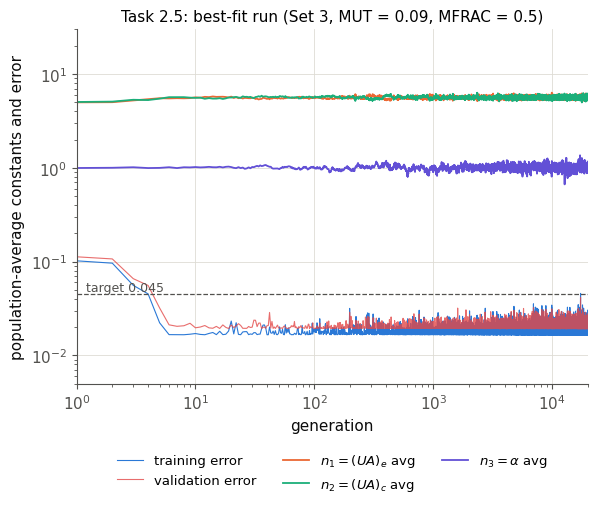

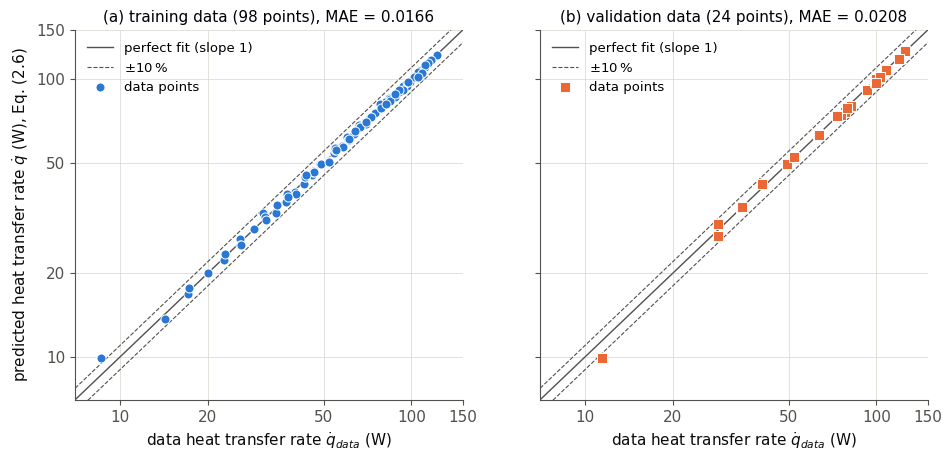

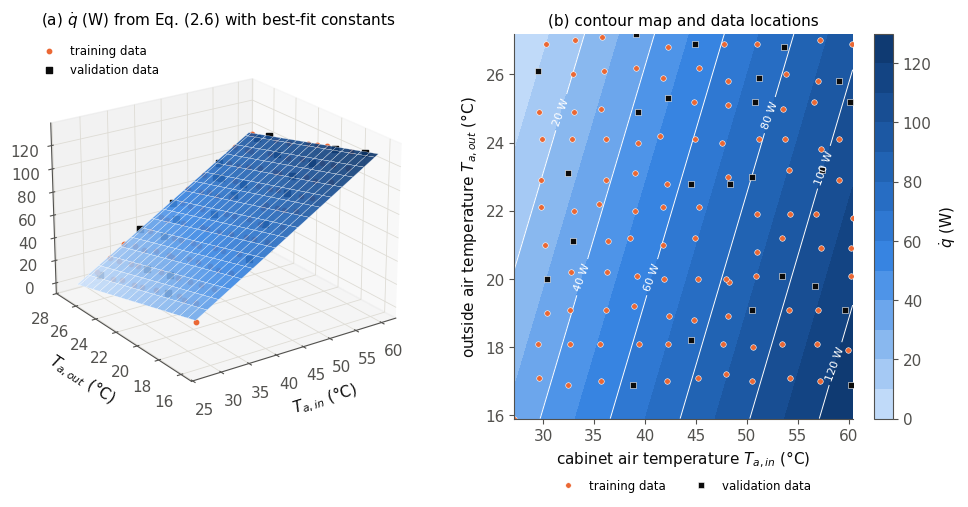

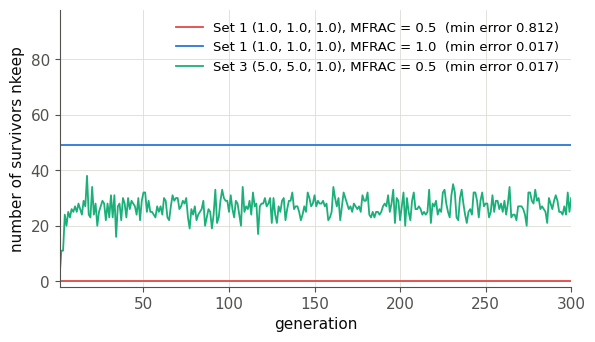

In [5]:
'''Task 2.5 - best fit (lowest TRAINING error of all runs; the validation set is not used to choose it),
   replayed with the same seed; training and validation mean absolute errors; plots.'''
from mpl_toolkits.mplot3d import Axes3D   # noqa: F401  (registers the 3d projection)
bestrun = min(study25 + ngen25, key=lambda d: d['F'])
print('best run:', bestrun['set'], bestrun['init'], 'MUT =', bestrun['MUT'], 'MFRAC =', bestrun['MFRAC'], 'NGEN =', bestrun['NGEN'], 'seed =', bestrun['seed'])
rb = run_GA(*bestrun['init'], NGEN=bestrun['NGEN'], MUT=bestrun['MUT'], MFRAC=bestrun['MFRAC'], rseed=bestrun['seed'])
n1min, n2min, n3min = rb['n1min'], rb['n2min'], rb['n3min']

def mae(D, n1, n2, n3):
    return numpy.mean([abs(row[2] - qdot_model(n1, n2, n3, row[0], row[1])) / abs(row[2]) for row in D])

Ftr, Fva, Fall = mae(ydata, n1min, n2min, n3min), mae(vdata, n1min, n2min, n3min), mae(yalldata, n1min, n2min, n3min)
hrm = numpy.mean([hrad(row[0], row[1]) for row in yalldata])
UAeff = 1. / (1. / n1min + 1. / (n2min * (1. + n3min * hrm / hcref)))
print('\nBEST FIT: (UA)e = n1 = %.4f W/C   (UA)c = n2 = %.4f W/C   alpha = n3 = %.4f' % (n1min, n2min, n3min))
print('mean absolute fractional error: training %.5f   validation %.5f   all data %.5f' % (Ftr, Fva, Fall))
print('overall conductance at the mean radiation coefficient hr = %.3f W/m2K : UA_eff = %.4f W/C' % (hrm, UAeff))

# evolution of the error (training and validation) and of the constants
fig, ax = plt.subplots(figsize=(6.6, 4.6))
g = numpy.arange(1, len(rb['gen']) + 1)
ax.plot(g, rb['aFerrmeanavgn'], color=C[0], lw=0.8, label='training error')
ax.plot(g, rb['aFerrval'], color=C[7], lw=0.8, alpha=0.8, label='validation error')
ax.plot(g, rb['n1avg'], color=C[1], lw=1.3, label=r'$n_1=(UA)_e$ avg')
ax.plot(g, rb['n2avg'], color=C[2], lw=1.3, label=r'$n_2=(UA)_c$ avg')
ax.plot(g, rb['n3avg'], color=C[6], lw=1.3, label=r'$n_3=\alpha$ avg')
ax.axhline(0.045, color=INK2, ls='--', lw=0.9); ax.text(1.2, 0.049, 'target 0.045', color=INK2, fontsize=9)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(1, len(g)); ax.set_ylim(0.005, 30)
ax.set_xlabel('generation'); ax.set_ylabel('population-average constants and error')
ax.set_title('Task 2.5: best-fit run (%s, MUT = %.2f, MFRAC = %.1f)' % (bestrun['set'], bestrun['MUT'], bestrun['MFRAC']))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3)
savefig('t25_evolution')

# log-log plot of predicted vs data heat transfer rate: training (circles) and validation (squares)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
xx = numpy.array([5, 200])
for a, D, mk, col, title in [(axs[0], ydata, 'o', C[0], '(a) training data (%d points), MAE = %.4f' % (ND, Ftr)),
                             (axs[1], vdata, 's', C[1], '(b) validation data (%d points), MAE = %.4f' % (NV, Fva))]:
    qd = [row[2] for row in D]; qp = [qdot_model(n1min, n2min, n3min, row[0], row[1]) for row in D]
    a.plot(xx, xx, '-', color=INK2, lw=1, label='perfect fit (slope 1)')
    a.plot(xx, 1.1 * xx, '--', color=INK2, lw=0.8, label=r'$\pm 10\,\%$')
    a.plot(xx, 0.9 * xx, '--', color=INK2, lw=0.8)
    a.loglog(qd, qp, mk, color=col, ms=6.5, mec='white', mew=0.7, label='data points')
    a.set_xlim(7, 150); a.set_ylim(7, 150)
    plain_log_ticks(a, [10, 20, 50, 100, 150], [10, 20, 50, 100, 150])
    a.set_xlabel(r'data heat transfer rate $\dot q_{data}$ (W)'); a.set_title(title)
    a.legend(loc='upper left')
axs[0].set_ylabel(r'predicted heat transfer rate $\dot q$ (W), Eq. (2.6)')
savefig('t25_parity')

# surface plot of qdot versus Ta,in and Ta,out over the range of the data
Yall = numpy.array(yalldata)
Ti_g = numpy.linspace(Yall[:, 0].min(), Yall[:, 0].max(), 50)
To_g = numpy.linspace(Yall[:, 1].min(), Yall[:, 1].max(), 50)
TI, TO = numpy.meshgrid(Ti_g, To_g)
QS = qdot_model(n1min, n2min, n3min, TI, TO)
fig = plt.figure(figsize=(12, 5.0))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.plot_surface(TI, TO, QS, cmap=BLUES, linewidth=0.2, edgecolor='white', rstride=3, cstride=3, alpha=0.9)
Yt, Yv = numpy.array(ydata), numpy.array(vdata)
ax.scatter(Yt[:, 0], Yt[:, 1], Yt[:, 2], c=C[1], s=10, depthshade=False, label='training data')
ax.scatter(Yv[:, 0], Yv[:, 1], Yv[:, 2], c=INK, marker='s', s=14, depthshade=False, label='validation data')
ax.set_xlabel(r'$T_{a,in}$ (°C)', labelpad=6); ax.set_ylabel(r'$T_{a,out}$ (°C)', labelpad=6)
ax.view_init(elev=22, azim=-125)
ax.legend(loc='upper left', fontsize=8.5)
ax.set_title(r'(a) $\dot q$ (W) from Eq. (2.6) with best-fit constants')
a2 = fig.add_subplot(1, 2, 2)
cs = a2.contourf(TI, TO, QS, levels=numpy.arange(0, 135, 10), cmap=BLUES)
cl = a2.contour(TI, TO, QS, levels=numpy.arange(0, 135, 20), colors='white', linewidths=0.7)
a2.clabel(cl, fmt='%d W', fontsize=8)
a2.plot(Yt[:, 0], Yt[:, 1], 'o', color=C[1], ms=4, mec='white', mew=0.4, label='training data')
a2.plot(Yv[:, 0], Yv[:, 1], 's', color=INK, ms=4.5, mec='white', mew=0.4, label='validation data')
cb = fig.colorbar(cs, ax=a2); cb.set_label(r'$\dot q$ (W)')
a2.set_xlabel(r'cabinet air temperature $T_{a,in}$ (°C)'); a2.set_ylabel(r'outside air temperature $T_{a,out}$ (°C)')
a2.set_title('(b) contour map and data locations'); a2.grid(False)
a2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8.5)
savefig('t25_surface')

# survivors per generation: frozen population when all errors are similar
fig, ax = plt.subplots(figsize=(6.6, 3.6))
for c, (name, MF) in enumerate([('Set 1', 0.5), ('Set 1', 1.0), ('Set 3', 0.5)]):
    r = run_GA(*SETS25[name], NGEN=300, MUT=0.09, MFRAC=MF, rseed=1, verbose=False)
    ax.plot(numpy.arange(1, 301), r['nkeephist'], color=C[[7, 0, 2][c]], lw=1.3,
            label='%s %s, MFRAC = %.1f  (min error %.3f)' % (name, SETS25[name], MF, r['aFerrmeanavgnMin']))
ax.set_xlabel('generation'); ax.set_ylabel('number of survivors nkeep')
ax.set_xlim(1, 300); ax.set_ylim(-2, ND)
ax.legend(loc='upper right')
savefig('t25_nkeep')

json.dump(dict(best=dict(n1=n1min, n2=n2min, n3=n3min, Ftrain=Ftr, Fval=Fva, Fall=Fall, UAeff=UAeff, hr_mean=hrm, kmin=rb['kmin'],
                         set=bestrun['set'], init=bestrun['init'], MUT=bestrun['MUT'], MFRAC=bestrun['MFRAC'], NGEN=bestrun['NGEN'], seed=bestrun['seed'],
                         n1end=rb['n1end'], n2end=rb['n2end'], n3end=rb['n3end'], Fend=rb['aFerrend'], n1ta=rb['n1ta'], n2ta=rb['n2ta'], n3ta=rb['n3ta']),
               split=dict(NALL=NALL, ND=ND, NV=NV, ival=[int(i) for i in ival]), table=table25, runs=study25, ngen=ngen25),
          open(RESDIR + 'task25.json', 'w'), indent=1)


reference minimum (training set): n1 = 26.4048  n2 = 3.1140  n3 = 0.5985   MAE = 0.016588


n1 fixed =    3.200 -> n2 = 17.2913  n3 = 10.2327  training MAE = 0.016591
n1 fixed =    8.336 -> n2 =  4.1786  n3 =  0.8329  training MAE = 0.016588
n1 fixed =   21.715 -> n2 =  3.1952  n3 =  0.6157  training MAE = 0.016588
n1 fixed =   56.569 -> n2 =  2.9302  n3 =  0.5597  training MAE = 0.016588
n1 fixed =  147.361 -> n2 =  2.8397  n3 =  0.5408  training MAE = 0.016588
n1 fixed =  383.877 -> n2 =  2.8065  n3 =  0.5339  training MAE = 0.016588
n1 fixed = 1000.000 -> n2 =  2.7939  n3 =  0.5313  training MAE = 0.016588


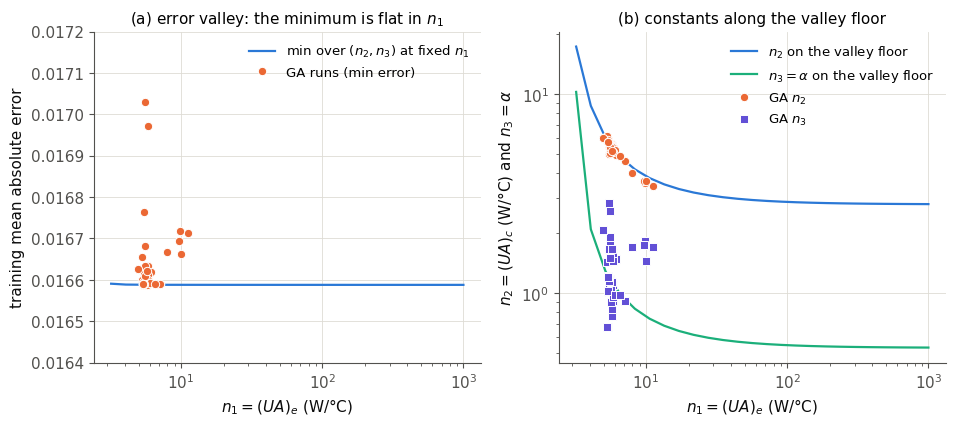

54 converged GA runs: n1 from 4.96 to 11.28, n2 from 3.44 to 6.11, n3 from 0.67 to 2.84, but UA_eff from 2.8935 to 2.9114 W/C


In [6]:
'''(added) Task 2.5 - are (UA)e, (UA)c and alpha individually determined by the data?
   (a) minimum training error when n1 = (UA)e is fixed and n2, n3 are re-optimised (deterministic
       minimisation of the same objective);  (b) constants found by all converged GA runs.'''
from scipy.optimize import minimize
Ytr = numpy.array(ydata)
Ti_t, To_t, q_t = Ytr[:, 0], Ytr[:, 1], Ytr[:, 2]

def Ftrain(n1, n2, n3):
    if n1 <= 0 or n2 <= 0:
        return 1e9
    return numpy.mean(numpy.abs(q_t - qdot_model(n1, n2, n3, Ti_t, To_t)) / q_t)

best = None
for x0 in [(5, 5, 1), (10, 3, 2), (3, 20, 1), (50, 3, 1)]:
    rr = minimize(lambda x: Ftrain(*x), x0, method='Nelder-Mead', options=dict(xatol=1e-10, fatol=1e-13, maxiter=20000))
    if best is None or rr.fun < best.fun:
        best = rr
print('reference minimum (training set): n1 = %.4f  n2 = %.4f  n3 = %.4f   MAE = %.6f' % (*best.x, best.fun))

n1fix = numpy.logspace(numpy.log10(3.2), 3, 25)
pf = []
for v in n1fix:
    bb = None
    for x0 in [(3, 1), (5, 2), (10, 5), (3, 0.1)]:
        rr = minimize(lambda y: Ftrain(v, y[0], y[1]), x0, method='Nelder-Mead', options=dict(xatol=1e-10, fatol=1e-13, maxiter=20000))
        if bb is None or rr.fun < bb.fun:
            bb = rr
    pf.append((v, bb.x[0], bb.x[1], bb.fun))
pf = numpy.array(pf)
for row in pf[::4]:
    print('n1 fixed = %8.3f -> n2 = %7.4f  n3 = %7.4f  training MAE = %.6f' % tuple(row))

conv = [d for d in study25 + ngen25 if d['F'] < 0.02]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.3))
a1.semilogx(pf[:, 0], pf[:, 3], '-', color=C[0], lw=1.6, label=r'min over $(n_2,n_3)$ at fixed $n_1$')
a1.semilogx([d['n1'] for d in conv], [d['F'] for d in conv], 'o', color=C[1], ms=6, mec='white', mew=0.7, label='GA runs (min error)')
a1.set_ylim(0.0164, 0.0172)
a1.set_xlabel(r'$n_1=(UA)_e$ (W/°C)'); a1.set_ylabel('training mean absolute error')
a1.set_title('(a) error valley: the minimum is flat in $n_1$')
a1.legend(loc='upper right')
a2.loglog(pf[:, 0], pf[:, 1], '-', color=C[0], lw=1.6, label=r'$n_2$ on the valley floor')
a2.loglog(pf[:, 0], pf[:, 2], '-', color=C[2], lw=1.6, label=r'$n_3=\alpha$ on the valley floor')
a2.loglog([d['n1'] for d in conv], [d['n2'] for d in conv], 'o', color=C[1], ms=6, mec='white', mew=0.7, label=r'GA $n_2$')
a2.loglog([d['n1'] for d in conv], [d['n3'] for d in conv], 's', color=C[6], ms=6, mec='white', mew=0.7, label=r'GA $n_3$')
a2.set_xlabel(r'$n_1=(UA)_e$ (W/°C)'); a2.set_ylabel(r'$n_2=(UA)_c$ (W/°C) and $n_3=\alpha$')
a2.set_title('(b) constants along the valley floor')
a2.legend(loc='upper right')
savefig('t25_degeneracy')
UAs = [1. / (1. / d['n1'] + 1. / (d['n2'] * (1. + d['n3'] * hrm / hcref))) for d in conv]
print('%d converged GA runs: n1 from %.2f to %.2f, n2 from %.2f to %.2f, n3 from %.2f to %.2f, but UA_eff from %.4f to %.4f W/C'
      % (len(conv), min(d['n1'] for d in conv), max(d['n1'] for d in conv), min(d['n2'] for d in conv), max(d['n2'] for d in conv),
         min(d['n3'] for d in conv), max(d['n3'] for d in conv), min(UAs), max(UAs)))
res = json.load(open(RESDIR + 'task25.json'))
res['ref'] = dict(n1=best.x[0], n2=best.x[1], n3=best.x[2], F=best.fun, Fval=mae(vdata, *best.x))
res['profile'] = pf.tolist()
res['conv_range'] = dict(n=len(conv), n1=[min(d['n1'] for d in conv), max(d['n1'] for d in conv)], n2=[min(d['n2'] for d in conv), max(d['n2'] for d in conv)],
                         n3=[min(d['n3'] for d in conv), max(d['n3'] for d in conv)], UAeff=[min(UAs), max(UAs)])
json.dump(res, open(RESDIR + 'task25.json', 'w'), indent=1)
